## library

In [32]:
import numpy as np, pandas as pd
print("numpy:", np.__version__, "| pandas:", pd.__version__)

numpy: 1.26.4 | pandas: 2.3.3


In [17]:
%pip install fasttext-wheel

Note: you may need to restart the kernel to use updated packages.


In [18]:
pip install contractions ftfy

Note: you may need to restart the kernel to use updated packages.


## Preprocessing

Standardized dimuat: 57,948 ulasan dari Standardized/dataset_standardized.csv
Filter batch ['batch_1']: 57,948 dari 57,948 ulasan dipakai

TABEL 0 — JUMLAH ULASAN PER TAHUN (cek: apakah tahun awal ada datanya?)
published_date                   2015  2016  2017  2018  2019  2020  2021  2022   2023  2024  2025  2026  TOTAL
beach_name          source                                                                                     
Kelingking Beach    GOOGLE          0     0     0     0     0     0     0     0   4559  3984   923   534  10000
                    TRIPADVISOR     0     0     0     2   591    88    21    43     77    80    61    34    997
Kuta Beach          GOOGLE          0     0     0     0     0  1085  1095  1789   1965  1652  1570   844  10000
                    TRIPADVISOR     0     0     0     0   573   161    19    49     48    71    54    24    999
Nusa Dua Beach      GOOGLE          0     4    14    71   117    71    79   103    225   238   436   250   1608
     

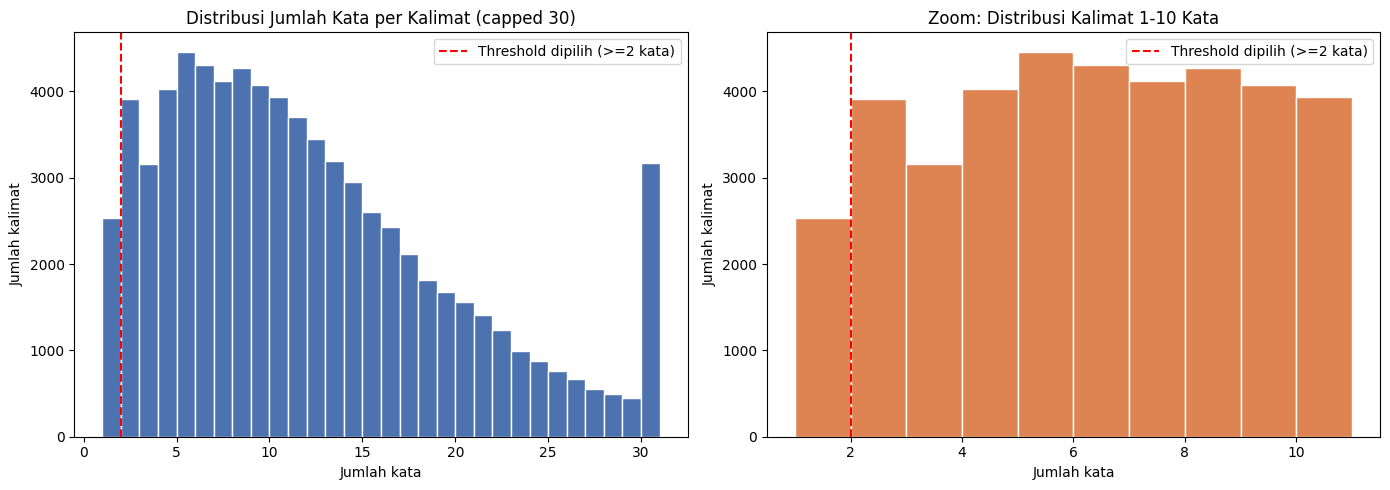


CONTOH KALIMAT YANG DIBUANG (word_count = 1, total: 2,535)
         beach_name source    sentence
         Kuta Beach GOOGLE       quiet
      Pandawa Beach GOOGLE          ok
Padang Padang Beach GOOGLE        good
         Kuta Beach GOOGLE        good
         Kuta Beach GOOGLE        cool
Padang Padang Beach GOOGLE        cool
      Pandawa Beach GOOGLE        good
        Sanur Beach GOOGLE    goodvjob
   Kelingking Beach GOOGLE    amazing!
     Seminyak Beach GOOGLE        nice
      Pandawa Beach GOOGLE         hot
         Kuta Beach GOOGLE interesting
         Kuta Beach GOOGLE        good
      Pandawa Beach GOOGLE        joss
        Sanur Beach GOOGLE        good

CONTOH KALIMAT YANG DIPERTAHANKAN (word_count = 2, total: 3,912)
         beach_name      source                sentence
      Pandawa Beach TRIPADVISOR sangat direkomendasikan
         Kuta Beach      GOOGLE    extremely congested.
      Pandawa Beach      GOOGLE             surf lesson
        Sanur Beach      G

In [ ]:
import os
import re
import fasttext
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import hashlib
import unicodedata
import contractions
import ftfy
from nltk.tokenize import sent_tokenize

# ==========================================
# 0. SETUP: NLTK + fastText (patch numpy 2.x)
# ==========================================
try:
    nltk.download('punkt', quiet=True)
    nltk.download('punkt_tab', quiet=True)
except Exception as e:
    print(f"⚠️ Gagal mengunduh NLTK resource otomatis: {e}")

if not getattr(np, "_ft_patched", False):
    _numpy_major = int(np.__version__.split(".")[0])
    if _numpy_major >= 2:
        _orig_array = np.array
        def _patched_array(object, copy=None, **kwargs):
            if copy is False:
                copy = None
            return _orig_array(object, copy=copy, **kwargs)
        np.array = _patched_array
        print(f"ℹ️ numpy {np.__version__} terdeteksi (>=2.0) -> patch fastText diterapkan.")
    else:
        print(f"ℹ️ numpy {np.__version__} terdeteksi (<2.0) -> patch fastText dilewati.")
    np._ft_patched = True

FASTTEXT_MODEL_PATH = "lid.176.ftz"
if not os.path.exists(FASTTEXT_MODEL_PATH):
    url = "https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.ftz"
    urllib.request.urlretrieve(url, FASTTEXT_MODEL_PATH)
ft_model = fasttext.load_model(FASTTEXT_MODEL_PATH)

LANG_CONFIDENCE_THRESHOLD = 0.60

# ==========================================
# KONFIGURASI INPUT / OUTPUT
# ==========================================

STANDARDIZED_FILE = 'Standardized/dataset_standardized.csv'

# Batch yang dipakai untuk analisis SKRIPSI (cutoff 21 Sept 2026).
THESIS_BATCHES = ['batch_1']

OUTPUT_DIR = 'Preprocessing'
os.makedirs(OUTPUT_DIR, exist_ok=True)

RAW_SENTENCES_FILE = os.path.join(OUTPUT_DIR, 'dataset_level_sentences_RAW.csv')
REVIEW_COUNTS_FILE = os.path.join(OUTPUT_DIR, 'review_counts_per_beach_platform.csv')
CSV_ENCODING = 'utf-8-sig'   # agar emoji/aksen tampil benar saat dibuka di Excel (pandas tetap bisa baca)
REMOVED_ROWS_FILE = os.path.join(OUTPUT_DIR, 'removed_rows_audit.csv')
REPROCESS = True

# ==========================================
# 1. CLEANING TAHAP 1
# ==========================================
def normalize_quotes(text):
    quote_map = {
        '\u2019': "'",  # ' RIGHT SINGLE QUOTATION MARK
        '\u2018': "'",  # ' LEFT SINGLE QUOTATION MARK
        '\u201c': '"',  # " LEFT DOUBLE QUOTATION MARK
        '\u201d': '"',  # " RIGHT DOUBLE QUOTATION MARK
        '\u02bc': "'",  # ʼ MODIFIER LETTER APOSTROPHE
        '\u0060': "'",  # ` GRAVE ACCENT -- kadang dipakai sbg pengganti apostrof
        '\u00b4': "'",  # ´ ACUTE ACCENT -- idem
        '\u2032': "'",  # ′ PRIME -- idem
    }
    for bad, good in quote_map.items():
        text = text.replace(bad, good)
    return text


def clean_text_safe_for_langid(text):
    if not isinstance(text, str):
        return ""
    text = ftfy.fix_text(text)  # perbaiki mojibake, "didnâ€™t"  -> "didn't"
    text = text.lower()
    text = normalize_quotes(text)
    text = text.replace('&', ' and ')  # "fish & chips" -> "fish and chips"
    text = contractions.fix(text)  # "don't" -> "do not"
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'@\w+|#\w+', ' ', text)
    # normalisasi huruf berulang (>=3) -> 2 huruf, HANYA huruf:
    # "soooo" -> "soo", "gooood" -> "good"; angka ("100000") & tanda baca ("...") tidak diubah
    text = re.sub(r'([a-z])\1{2,}', r'\1\1', text)
    text = re.sub(r'\s+', ' ', text).strip()  # normalisasi spasi
    return text

# ==========================================
# 2. CLEANING TAHAP 2 -- untuk pemodelan
# ==========================================
def strip_accents(text):  # (é, ñ, à, dst.) -> (e, n, a)
    nfkd = unicodedata.normalize('NFKD', text)
    return ''.join(c for c in nfkd if not unicodedata.combining(c))

def clean_text_for_modeling(text):
    text = strip_accents(text)  # "café" -> "cafe", SEBELUM huruf non-ASCII dibuang
    text = re.sub(r'[^a-zA-Z0-9\s.,!?\'"\-]', ' ', text)  # hapus non-ASCII, emoji, simbol aneh
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def count_real_words(text):
    tokens = text.split()
    return sum(1 for t in tokens if re.search(r'[a-zA-Z]', t))

def detect_lang_fasttext(text):
    text = str(text).replace("\n", " ").strip()
    if not text:
        return "unknown", 0.0
    labels, probs = ft_model.predict(text, k=1)
    lang = labels[0].replace("__label__", "")  # isi bucket bahasa
    confidence = float(probs[0])  # probabilitas prediksi bahasa
    return lang, confidence

def bucket_lang(detected_lang, confidence, threshold=LANG_CONFIDENCE_THRESHOLD):
    if confidence < threshold:
        return 'English'   
    elif detected_lang == 'en':
        return 'English'
    elif detected_lang == 'id':
        return 'Indonesian'
    else:
        return 'Other/Unknown'

def count_sentences(text_series):
    total = 0
    for t in text_series:
        cleaned = clean_text_safe_for_langid(t)
        if not cleaned:
            continue
        total += len(sent_tokenize(cleaned))
    return total

# ==========================================
# 3. PROSES UTAMA PER PANTAI x PLATFORM
# ==========================================
review_level_counts = []
removed_rows_log = []

AUDIT_COLUMNS = ['beach_name', 'source', 'reason', 'review_id', 'reviewer_name',
                 'published_date', 'rating', 'review_text']

def make_review_id_parent(beach_name, source, row):
    """review_id dari file standardized sudah stabil (gr:<reviewId> / ta:<nomor review>).
    Hash hanya dipakai kalau review_id kosong."""
    rid = row.get('review_id')
    if pd.notna(rid) and str(rid).strip() != "":
        return str(rid)
    reviewer = row.get('_reviewer_key')
    if pd.notna(reviewer) and str(reviewer).strip() != "":
        base = f"{reviewer}_{row.get('clean_text_v1')}"
    else:
        base = f"anon_{row.get('_local_id')}_{row.get('clean_text_v1')}"
    short_hash = hashlib.md5(base.encode('utf-8')).hexdigest()[:10]
    return f"{beach_name}_{source}_{short_hash}"

def process_beach_data(df, beach_name, source):
    df = df.reset_index(drop=True).copy()
    n_raw = len(df)
    df['_local_id'] = df.index

    # kolom dari file standardized -> nama kolom internal
    df['text_raw'] = df['review_text']
    df['_reviewer_key'] = df['reviewer_name']
    df['_native_review_id'] = df['review_id']

    n_sentences_raw = count_sentences(df['text_raw'])

    def _tag_and_log(removed_df, reason):
        if len(removed_df) == 0:
            return
        tagged = removed_df.copy()
        tagged['reason'] = reason
        removed_rows_log.append(tagged.reindex(columns=AUDIT_COLUMNS))

    before_text = df.copy()

    # Hapus review nan/null (termasuk ulasan yang hanya rating tanpa teks)
    df_step1 = df.dropna(subset=['text_raw']).copy()
    removed_na = before_text[~before_text['_local_id'].isin(df_step1['_local_id'])]
    _tag_and_log(removed_na, 'empty_text')
    df_step1['text_raw'] = df_step1['text_raw'].astype(str).str.strip()

    # Hapus review yang kosong setelah strip (mis. hanya spasi)
    df_step2 = df_step1[df_step1['text_raw'] != ""].copy()
    removed_empty = df_step1[~df_step1['_local_id'].isin(df_step2['_local_id'])]
    _tag_and_log(removed_empty, 'empty_text')

    df = df_step2
    n_after_empty_review_removed = len(df)

    # Parsing date (standardized sudah YYYY-MM-DD; 'mixed' tetap dipakai untuk jaga-jaga)
    parsed_dates = pd.to_datetime(df['published_date'], errors='coerce', utc=True, format='mixed')
    df['published_date_clean'] = parsed_dates.dt.strftime('%Y-%m-%d')
    df['year_temp'] = parsed_dates.dt.year

    mask_date_invalid = df['published_date_clean'].isna() | df['year_temp'].isna()
    removed_date_invalid = df[mask_date_invalid]
    _tag_and_log(removed_date_invalid, 'invalid_date')

    # Buang review sebelum 2019
    df_valid_date = df[~mask_date_invalid].copy()
    mask_before_2019 = df_valid_date['year_temp'] < 2019
    removed_before_2019 = df_valid_date[mask_before_2019]
    _tag_and_log(removed_before_2019, 'before_2019')

    df = df_valid_date[~mask_before_2019].copy()
    n_after_year_filter = len(df)

    # ==========================================
    # Deduplikasi mencegah review ganda
    # ==========================================
    df['clean_text_v1'] = df['text_raw'].apply(clean_text_safe_for_langid)

    # --- TAHAP 1: DEDUPLIKASI BERDASARKAN ID REVIEW ---
    has_native_id = df['_native_review_id'].notna() & (df['_native_review_id'].astype(str).str.strip() != "")
    df_with_id = df[has_native_id].copy()
    df_without_id = df[~has_native_id].copy()

    dup_native_mask = df_with_id.duplicated(subset=['_native_review_id'], keep='first')
    removed_dup_native = df_with_id[dup_native_mask]
    _tag_and_log(removed_dup_native, 'duplicate_review_id')

    df_with_id_clean = df_with_id[~dup_native_mask]
    df_after_native_dedup = pd.concat([df_with_id_clean, df_without_id], ignore_index=False)

    # --- TAHAP 2: DEDUPLIKASI BERDASARKAN NAMA REVIEWER & TEKS ---
    has_reviewer_key = df_after_native_dedup['_reviewer_key'].notna() & \
                       (df_after_native_dedup['_reviewer_key'].astype(str).str.strip() != "")
    df_with_reviewer = df_after_native_dedup[has_reviewer_key].copy()
    df_without_reviewer = df_after_native_dedup[~has_reviewer_key].copy()

    # Hapus ulasan jika nama reviewer sama DAN teks (clean_text_v1) persis sama
    dup_reviewer_text_mask = df_with_reviewer.duplicated(subset=['_reviewer_key', 'clean_text_v1'], keep='first')
    removed_dup_reviewer_text = df_with_reviewer[dup_reviewer_text_mask]
    _tag_and_log(removed_dup_reviewer_text, 'duplicate_reviewer_and_text')

    df_with_reviewer_clean = df_with_reviewer[~dup_reviewer_text_mask]

    df = pd.concat([df_with_reviewer_clean, df_without_reviewer], ignore_index=False)
    df = df.reset_index(drop=True)
    n_after_dedup = len(df)

    rows_sentences = []

    for review_idx, row in df.iterrows():
        raw_text = row['clean_text_v1']
        if not raw_text:
            continue
        review_id_parent = make_review_id_parent(beach_name, source, row)
        for sentence in sent_tokenize(raw_text):
            sentence_clean = sentence.strip()
            if not sentence_clean:
                continue
            rows_sentences.append({
                'beach_name': beach_name,
                'source': source,
                'scrape_batch': row['scrape_batch'],
                'review_id_parent': review_id_parent,
                'reviewer_name': row['reviewer_name'],
                'published_date': row['published_date_clean'],
                'travel_date': row['travel_date'],   # hanya TA
                'trip_type': row['trip_type'],       # hanya TA
                'rating': row['rating'],
                'sentence_raw': sentence_clean,
            })

    df_sentences = pd.DataFrame(rows_sentences)
    n_sentences_after_dedup = len(df_sentences)

    review_level_counts.append({
        'beach_name': beach_name,
        'source': source,
        'n_raw': n_raw,
        'n_after_empty_review_removed': n_after_empty_review_removed,
        'n_after_year_filter': n_after_year_filter,
        'n_after_dedup': n_after_dedup,
        'n_sentences_raw': n_sentences_raw,
        'n_sentences_after_dedup': n_sentences_after_dedup,
    })

    return df_sentences

def _print_pivot(df_counts, value_col, title):
    print("\n" + "="*70)
    print(title)
    print("="*70)
    pivot = df_counts.pivot_table(
        index='beach_name', columns='source', values=value_col, aggfunc='sum', fill_value=0
    )
    pivot['TOTAL'] = pivot.sum(axis=1)
    total_row = pivot.sum(axis=0)
    total_row.name = 'TOTAL'
    pivot = pd.concat([pivot, total_row.to_frame().T])
    print(pivot.to_string())
    return pivot

def _print_funnel(df_counts, cols, title):
    print("\n" + "="*70)
    print(title)
    print("="*70)
    funnel = df_counts.groupby('source')[cols].sum()
    total_row = funnel.sum(axis=0)
    total_row.name = 'TOTAL'
    funnel = pd.concat([funnel, total_row.to_frame().T])
    print(funnel.to_string())
    return funnel

def _print_crosstab_with_totals(series_a, series_b, title, values_are_pct=False):
    print("\n" + "="*70)
    print(title)
    print("="*70)
    ct = pd.crosstab(series_a, series_b, margins=True, margins_name='TOTAL')
    if values_are_pct:
        print(ct.round(2).to_string())
    else:
        print(ct.to_string())
    return ct

def print_all_summaries(review_counts_df):
    results = {}

    results['tabel1_dokumen_raw_per_pantai'] = _print_pivot(
        review_counts_df, 'n_raw',
        "TABEL 1 — JUMLAH DOKUMEN (ULASAN) RAW PER PANTAI & PLATFORM"
    )
    results['tabel2_funnel_dokumen'] = _print_funnel(
        review_counts_df,
        ['n_raw', 'n_after_empty_review_removed', 'n_after_year_filter', 'n_after_dedup'],
        "TABEL 2 — FUNNEL JUMLAH DOKUMEN (ULASAN) PER TAHAP FILTER (PER PLATFORM)"
    )

    sentence_cols = ['n_sentences_raw', 'n_sentences_after_dedup']
    has_sentence_cols = all(c in review_counts_df.columns for c in sentence_cols)

    if has_sentence_cols:
        results['tabel3_kalimat_final_per_pantai'] = _print_pivot(
            review_counts_df, 'n_sentences_after_dedup',
            "TABEL 3 — JUMLAH KALIMAT FINAL (SETELAH SEMUA FILTER) PER PANTAI & PLATFORM"
        )
    else:
        results['tabel3_kalimat_final_per_pantai'] = None
        print("\n⚠️ File cache belum punya kolom level-kalimat.")

    return results


if os.path.exists(RAW_SENTENCES_FILE) and not REPROCESS:
    print(f"Memuat '{RAW_SENTENCES_FILE}' yang sudah ada...")
    df_raw = pd.read_csv(RAW_SENTENCES_FILE, encoding=CSV_ENCODING)

    if os.path.exists(REVIEW_COUNTS_FILE):
        review_counts_df = pd.read_csv(REVIEW_COUNTS_FILE)
        summary_tables = print_all_summaries(review_counts_df)
    else:
        print("⚠️ Rekap funnel belum ada — jalankan sekali dengan REPROCESS=True.")

    if os.path.exists(REMOVED_ROWS_FILE):
        print(f"\nAudit baris terbuang tersedia di: {REMOVED_ROWS_FILE}")
    else:
        print("⚠️ Audit baris terbuang belum ada — jalankan sekali dengan REPROCESS=True.")

else:
    import traceback

    # --- baca file standardized ---
    df_std = pd.read_csv(STANDARDIZED_FILE, dtype=str, keep_default_na=False, na_values=[''])
    print(f"Standardized dimuat: {len(df_std):,} ulasan dari {STANDARDIZED_FILE}")

    # --- filter batch skripsi (sebelum funnel, supaya Tabel 1-3 konsisten) ---
    if THESIS_BATCHES is not None:
        n_before = len(df_std)
        df_std = df_std[df_std['scrape_batch'].isin(THESIS_BATCHES)].copy()
        print(f"Filter batch {THESIS_BATCHES}: {len(df_std):,} dari {n_before:,} ulasan dipakai")
        if len(df_std) == 0:
            raise ValueError(f"Tidak ada ulasan dengan scrape_batch {THESIS_BATCHES}. "
                             f"Batch yang ada: {sorted(pd.read_csv(STANDARDIZED_FILE, usecols=['scrape_batch'])['scrape_batch'].unique())}")

    # --- TABEL 0: cakupan tahun per pantai x platform (cek data terpotong limit scraper) ---
    _year = pd.to_datetime(df_std['published_date'], errors='coerce', utc=True, format='mixed').dt.year
    print("\n" + "="*70)
    print("TABEL 0 — JUMLAH ULASAN PER TAHUN (cek: apakah tahun awal ada datanya?)")
    print("="*70)
    print(pd.crosstab([df_std['beach_name'], df_std['source']], _year,
                      margins=True, margins_name='TOTAL').to_string())

    all_dfs = []
    for (beach_name, source), g in df_std.groupby(['beach_name', 'source'], sort=False):
        try:
            all_dfs.append(process_beach_data(g, beach_name, source))
        except Exception as e:
            print(f"Gagal memproses {beach_name} | {source}: {e}")
            traceback.print_exc()

    df_raw = pd.concat(all_dfs, ignore_index=True)
    # (disimpan setelah deteksi bahasa di bagian 5, supaya kolom bahasa ikut)

    review_counts_df = pd.DataFrame(review_level_counts)
    review_counts_df.to_csv(REVIEW_COUNTS_FILE, index=False, encoding=CSV_ENCODING)

    summary_tables = print_all_summaries(review_counts_df)

    if removed_rows_log:
        removed_df = pd.concat(removed_rows_log, ignore_index=True)
        removed_df.to_csv(REMOVED_ROWS_FILE, index=False, encoding=CSV_ENCODING)

        print("\n" + "="*70)
        print("RINGKASAN ULASAN TERBUANG PER ALASAN")
        print("="*70)
        print(pd.crosstab(removed_df['reason'], removed_df['source'],
                          margins=True, margins_name='TOTAL').to_string())
        print(f"\nTersimpan lengkap: {REMOVED_ROWS_FILE} ({len(removed_df):,} baris)")
    else:
        print("Tidak ada baris yang terbuang pada tahap filtering ini.")

# ==========================================
# 5. LANGUAGE DETECTION (fastText)
# ==========================================
# deteksi hanya jika belum ada (cache); bucket SELALU dihitung ulang -> ganti threshold tanpa deteksi ulang
if 'detected_lang' not in df_raw.columns or 'lang_confidence' not in df_raw.columns:
    df_raw[['detected_lang', 'lang_confidence']] = df_raw['sentence_raw'].apply(
        lambda x: pd.Series(detect_lang_fasttext(x))
    )
df_raw['lang_bucket'] = df_raw.apply(
    lambda row: bucket_lang(row['detected_lang'], row['lang_confidence']), axis=1
)

RAW_COLUMN_ORDER = ['beach_name', 'source', 'scrape_batch', 'review_id_parent', 'reviewer_name',
                    'published_date', 'travel_date', 'trip_type', 'rating', 'sentence_raw',
                    'detected_lang', 'lang_confidence', 'lang_bucket']
df_raw = df_raw[[c for c in RAW_COLUMN_ORDER if c in df_raw.columns]]
df_raw.to_csv(RAW_SENTENCES_FILE, index=False, encoding=CSV_ENCODING)
print(f"Tersimpan: {RAW_SENTENCES_FILE} ({len(df_raw):,} kalimat)")

print("\n" + "="*70)
print("TABEL 4 — DISTRIBUSI BUCKET BAHASA (KESELURUHAN)")
print("="*70)
print((df_raw['lang_bucket'].value_counts(normalize=True) * 100).to_string())

lang_by_platform_count = _print_crosstab_with_totals(
    df_raw['source'], df_raw['lang_bucket'],
    "TABEL 5 — DISTRIBUSI BUCKET BAHASA PER PLATFORM (JUMLAH KALIMAT)"
)

print("\n" + "="*70)
print("TABEL 6 — DISTRIBUSI BUCKET BAHASA PER PLATFORM (PERSENTASE DALAM PLATFORM)")
print("="*70)
lang_by_platform_pct = pd.crosstab(df_raw['source'], df_raw['lang_bucket'], normalize='index') * 100
print(lang_by_platform_pct.round(2).to_string())

# --- Cek kalimat low-confidence yang masuk bucket English (untuk dicek manual) ---
low_conf_en = df_raw[(df_raw['lang_bucket'] == 'English') &
                     (df_raw['lang_confidence'] < LANG_CONFIDENCE_THRESHOLD)]
print(f"\nKalimat English dari low-confidence (< {LANG_CONFIDENCE_THRESHOLD}): {len(low_conf_en):,} "
      f"({len(low_conf_en)/max((df_raw['lang_bucket'] == 'English').sum(), 1)*100:.2f}% dari bucket English)")
if len(low_conf_en) > 0:
    low_conf_en.to_csv(os.path.join(OUTPUT_DIR, 'lowconf_english_check.csv'), index=False, encoding=CSV_ENCODING)
    print("Disimpan ke: lowconf_english_check.csv -> cek sampel, berapa yang benar-benar English")
    print(low_conf_en[['source', 'detected_lang', 'lang_confidence', 'sentence_raw']]
          .sample(min(10, len(low_conf_en)), random_state=42).to_string(index=False))

english_df = df_raw[df_raw['lang_bucket'] == 'English'].copy()
indonesian_df = df_raw[df_raw['lang_bucket'] == 'Indonesian'].copy()
other_df = df_raw[df_raw['lang_bucket'] == 'Other/Unknown'].copy()
# (file final per bahasa disimpan di bagian 8 -- FINAL STEP)

# ==========================================
# 6. CLEANING TAHAP 2
# ==========================================
english_df['sentence'] = english_df['sentence_raw'].apply(clean_text_for_modeling)

empty_after_aggressive_clean = english_df[english_df['sentence'] == ""].copy()
if len(empty_after_aggressive_clean) > 0:
    empty_after_aggressive_clean['reason'] = 'empty_after_aggressive_clean'
    empty_after_aggressive_clean = empty_after_aggressive_clean[
        ['beach_name', 'source', 'reason', 'review_id_parent', 'reviewer_name',
         'sentence_raw', 'detected_lang', 'lang_confidence']]
    empty_after_aggressive_clean.to_csv(os.path.join(OUTPUT_DIR, 'removed_empty_after_aggressive_clean.csv'),
                                        index=False, encoding=CSV_ENCODING)
    print(f"\n⚠️ {len(empty_after_aggressive_clean):,} kalimat menjadi kosong setelah cleaning agresif "
          f"-> dicatat di 'removed_empty_after_aggressive_clean.csv'")

english_df = english_df[english_df['sentence'] != ""].copy()
english_df['word_count'] = english_df['sentence'].apply(count_real_words)

# ==========================================
# 6b. CEK HTML entity
# ==========================================
html_entity_pattern = re.compile(r'&[a-zA-Z]+;|&#\d+;')
has_entity_mask = english_df['sentence'].str.contains(html_entity_pattern, regex=True, na=False)

print("\n" + "="*70)
print("CEK HTML ENTITY")
print("="*70)
print(f"Kalimat mengandung HTML entity: {has_entity_mask.sum():,} "
      f"({has_entity_mask.sum()/len(english_df)*100:.3f}% dari dataset English)")

if has_entity_mask.sum() > 0:
    entity_examples = english_df[has_entity_mask][['beach_name', 'source', 'sentence_raw', 'sentence']]
    entity_examples.to_csv(os.path.join(OUTPUT_DIR, 'html_entity_found.csv'), index=False, encoding=CSV_ENCODING)
    print("Detail lengkap disimpan ke: html_entity_found.csv")
    print("\nContoh:")
    print(entity_examples.head(10).to_string(index=False))
    print("\n⚠️ HTML entity ditemukan -> pertimbangkan tambahkan html.unescape() "
          "ke clean_text_safe_for_langid, lalu jalankan ulang dengan REPROCESS=True.")
else:
    print("Tidak ditemukan sisa HTML entity -- tidak perlu perubahan pada pipeline.")

# ==========================================
# 7. DISTRIBUSI JUMLAH KATA
# ==========================================
wc = english_df['word_count']

print("\n" + "="*70)
print("TABEL 7 — STATISTIK JUMLAH KATA PER KALIMAT (dataset English final)")
print("="*70)
print(wc.describe())

print("\n" + "="*70)
print("TABEL 8 — DISTRIBUSI JUMLAH KATA PER KALIMAT (lengkap, semua nilai)")
print("="*70)
total = len(wc)
exact_counts_full = wc.value_counts().sort_index()

wc_distribution_full = exact_counts_full.reset_index()
wc_distribution_full.columns = ['word_count', 'jumlah_kalimat']
wc_distribution_full['persentase'] = (wc_distribution_full['jumlah_kalimat'] / total * 100).round(3)
wc_distribution_full.to_csv(os.path.join(OUTPUT_DIR, 'word_count_distribution_full.csv'), index=False, encoding=CSV_ENCODING)

print(f"Distribusi lengkap ({len(wc_distribution_full)} nilai word_count unik) "
      f"disimpan ke: word_count_distribution_full.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

wc_capped = wc.clip(upper=30)
axes[0].hist(wc_capped, bins=range(1, 32), color='#4C72B0', edgecolor='white')
axes[0].axvline(2, color='red', linestyle='--', label='Threshold dipilih (>=2 kata)')
axes[0].set_title('Distribusi Jumlah Kata per Kalimat (capped 30)')
axes[0].set_xlabel('Jumlah kata'); axes[0].set_ylabel('Jumlah kalimat'); axes[0].legend()

wc_low = wc[wc <= 10]
axes[1].hist(wc_low, bins=range(1, 12), color='#DD8452', edgecolor='white')
axes[1].axvline(2, color='red', linestyle='--', label='Threshold dipilih (>=2 kata)')
axes[1].set_title('Zoom: Distribusi Kalimat 1-10 Kata')
axes[1].set_xlabel('Jumlah kata'); axes[1].set_ylabel('Jumlah kalimat'); axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'word_count_distribution.png'), dpi=150)
plt.show()

removed_1 = english_df[english_df['word_count'] == 1]
print("\n" + "="*70)
print(f"CONTOH KALIMAT YANG DIBUANG (word_count = 1, total: {len(removed_1):,})")
print("="*70)
print(removed_1[['beach_name', 'source', 'sentence']].sample(min(15, len(removed_1)), random_state=42).to_string(index=False))

kept_2 = english_df[english_df['word_count'] == 2]
print("\n" + "="*70)
print(f"CONTOH KALIMAT YANG DIPERTAHANKAN (word_count = 2, total: {len(kept_2):,})")
print("="*70)
print(kept_2[['beach_name', 'source', 'sentence']].sample(min(15, len(kept_2)), random_state=42).to_string(index=False))


In [ ]:
# ==========================================
# 8. FINAL STEP PREPROCESSING
# ==========================================
FINAL_EN_FILE    = os.path.join(OUTPUT_DIR, 'dataset_final_sentences_english.csv')
FINAL_ID_FILE    = os.path.join(OUTPUT_DIR, 'dataset_final_sentences_indonesian.csv')
FINAL_OTHER_FILE = os.path.join(OUTPUT_DIR, 'dataset_final_sentences_other_unknown.csv') 
MIN_WORDS = 2

# ---------- ENGLISH (dataset utama untuk pemodelan) ----------
df_final = english_df[english_df['word_count'] >= MIN_WORDS].copy().reset_index(drop=True)

dup_final_mask = df_final.duplicated(subset=['beach_name', 'sentence'], keep=False)
print(f"Kalimat identik dari ulasan berbeda (per pantai): {dup_final_mask.sum():,} "
      f"({dup_final_mask.mean()*100:.2f}%) -> dipertahankan")
print("10 kalimat paling sering muncul:")
print(df_final['sentence'].value_counts().head(10).to_string())

df_final = df_final.drop(columns=['sentence_raw', 'detected_lang', 'lang_confidence', 'lang_bucket'], errors='ignore')
df_final.to_csv(FINAL_EN_FILE, index=False, encoding=CSV_ENCODING)

# ---------- INDONESIAN (cleaning & filter sama dengan English) ----------
df_final_id = indonesian_df.copy()
df_final_id['sentence'] = df_final_id['sentence_raw'].apply(clean_text_for_modeling)
df_final_id = df_final_id[df_final_id['sentence'] != ""].copy()
df_final_id['word_count'] = df_final_id['sentence'].apply(count_real_words)
df_final_id = df_final_id[df_final_id['word_count'] >= MIN_WORDS].reset_index(drop=True)
df_final_id = df_final_id.drop(columns=['sentence_raw', 'detected_lang', 'lang_confidence', 'lang_bucket'], errors='ignore')
df_final_id.to_csv(FINAL_ID_FILE, index=False, encoding=CSV_ENCODING)

# ---------- OTHER/UNKNOWN (disimpan apa adanya, TANPA cleaning agresif) ----------.
df_final_other = other_df.copy().reset_index(drop=True)
df_final_other['sentence'] = df_final_other['sentence_raw']
df_final_other = df_final_other.drop(columns=['sentence_raw', 'lang_bucket'], errors='ignore')
df_final_other.to_csv(FINAL_OTHER_FILE, index=False, encoding=CSV_ENCODING)

df_final['published_date_dt'] = pd.to_datetime(df_final['published_date'])
df_final['year'] = df_final['published_date_dt'].dt.year

print("\n" + "="*70)
print("!! SELESAI !! RINGKASAN DATASET AKHIR !!")
print("="*70)
print(f"English       : {FINAL_EN_FILE} ({len(df_final):,} kalimat)  <- dataset pemodelan")
print(f"Indonesian    : {FINAL_ID_FILE} ({len(df_final_id):,} kalimat)")
print(f"Other/Unknown : {FINAL_OTHER_FILE} ({len(df_final_other):,} kalimat)")

print(f"\nJumlah Destinasi Pantai : {df_final['beach_name'].nunique()}")
print("Distribusi Sumber Data (Platform) -- English final:")
print(df_final['source'].value_counts().to_string())
print()

print("FUNNEL LEVEL KALIMAT (English)")
print(f"Setelah remove NaN, filter tahun, dedup           : {len(df_raw):,}")
print(f"Setelah filter bahasa (English only)              : {len(english_df) + len(empty_after_aggressive_clean):,}")
print(f"Setelah cleaning agresif (buang yang jadi kosong) : {len(english_df):,}")
print(f"Setelah filter word_count >= {MIN_WORDS} (dataset final)    : {len(df_final):,}")


Kalimat identik dari ulasan berbeda (per pantai): 3,728 (5.15%) -> dipertahankan
10 kalimat paling sering muncul:
sentence
beautiful beach            133
very good                  100
nice beach                  93
beautiful beach.            72
nice place                  72
very beautiful              72
nice view                   48
beautiful place             44
nice beach.                 43
the beach is beautiful.     40

!! SELESAI !! RINGKASAN DATASET AKHIR !!
English       : Preprocessing/dataset_final_sentences_english.csv (72,374 kalimat)  <- dataset pemodelan
Indonesian    : Preprocessing/dataset_final_sentences_indonesian.csv (561 kalimat)
Other/Unknown : Preprocessing/dataset_final_sentences_other_unknown.csv (5,048 kalimat)

Jumlah Destinasi Pantai : 7
Distribusi Sumber Data (Platform) -- English final:
source
GOOGLE         56737
TRIPADVISOR    15637

FUNNEL LEVEL KALIMAT (English)
Setelah remove NaN, filter tahun, dedup           : 81,347
Setelah filter bahasa (Engli

## Visualisasi Preprocessing

In [2]:
import pandas as pd
import os

file_path = 'Preprocessing/dataset_final_sentences_english.csv' 

if os.path.exists(file_path):
    print(f"Membaca file: {file_path}\n")
    df = pd.read_csv(file_path)

    print("="*50)
    print("INFORMASI UMUM DATASET")
    print("="*50)
    df.info()

    print("\n" + "="*50)
    print("CUPLIKAN DATA (5 BARIS PERTAMA)")
    print("="*50)

    pd.set_option('display.max_columns', None) 
    pd.set_option('display.width', 1000)
    print(df.head())

else:
    print(f"❌ File tidak ditemukan di path: {file_path}")
    print("Pastikan folder 'Standardized' berada di direktori yang sama dengan script ini.")

Membaca file: Preprocessing/dataset_final_sentences_english.csv

INFORMASI UMUM DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72374 entries, 0 to 72373
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   beach_name        72374 non-null  object
 1   source            72374 non-null  object
 2   scrape_batch      72374 non-null  object
 3   review_id_parent  72374 non-null  object
 4   reviewer_name     72372 non-null  object
 5   published_date    72374 non-null  object
 6   travel_date       15627 non-null  object
 7   trip_type         15627 non-null  object
 8   rating            72374 non-null  int64 
 9   sentence          72374 non-null  object
 10  word_count        72374 non-null  int64 
dtypes: int64(2), object(9)
memory usage: 6.1+ MB

CUPLIKAN DATA (5 BARIS PERTAMA)
         beach_name  source scrape_batch                                   review_id_parent             reviewer_name publ

python(69926) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


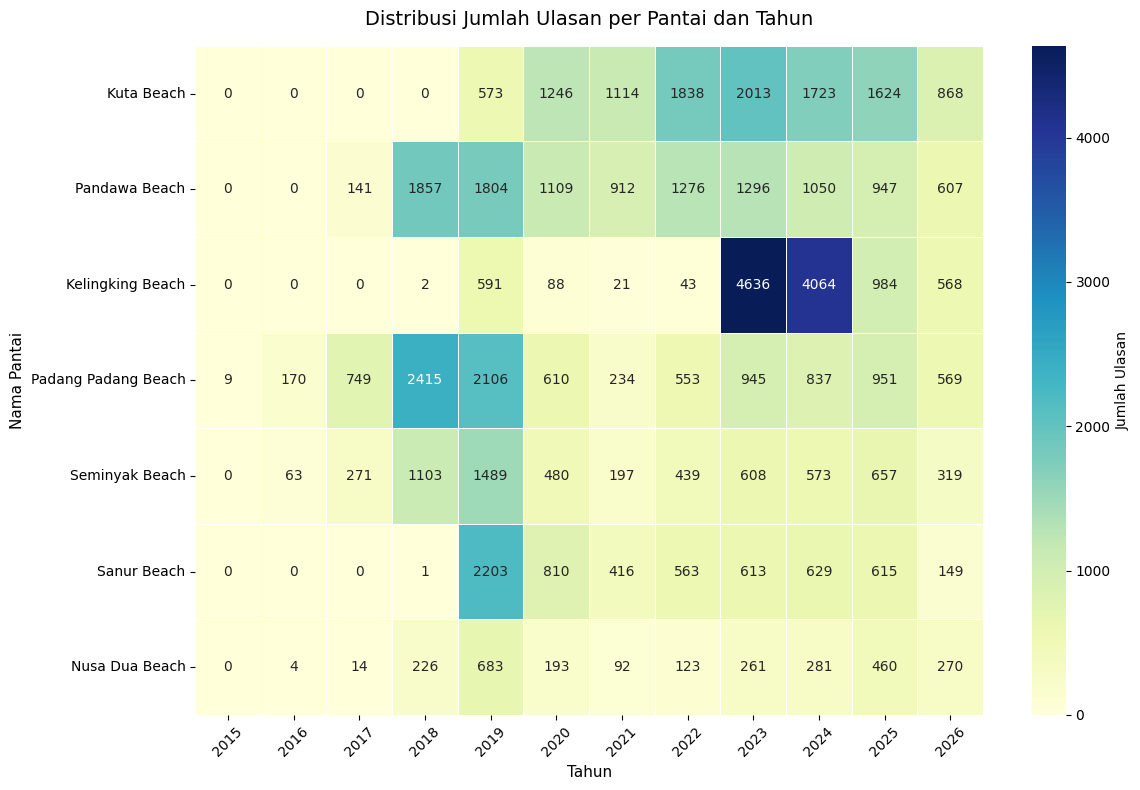

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Buat tabel pivot untuk menghitung total ulasan (gabungan platform)
pivot_heatmap = pd.crosstab(d['beach_name'], d['tahun'])

# Reindex agar urutan pantai dan tahun sesuai dengan daftar urutan Anda
pivot_heatmap = pivot_heatmap.reindex(index=pantai_urut, columns=tahun_urut, fill_value=0)

# 3. Visualisasi Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(pivot_heatmap, 
            annot=True,        # Menampilkan angka di dalam setiap kotak
            fmt="d",           # Format angka desimal biasa (integer)
            cmap="YlGnBu",     # Skema warna (kuning ke hijau ke biru tua)
            linewidths=0.5,    # Ketebalan garis pemisah antar kotak
            cbar_kws={'label': 'Jumlah Ulasan'})

plt.title('Distribusi Jumlah Ulasan per Pantai dan Tahun', fontsize=14, pad=15)
plt.xlabel('Tahun', fontsize=11)
plt.ylabel('Nama Pantai', fontsize=11)

plt.xticks(rotation=45) 
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/heatmap_ulasan_per_pantai_tahun.png', dpi=150, bbox_inches='tight')
plt.show()